# Gemma-2B — Repeatability of Mathematics 500 evaluation

**Study design.** Fifteen complete evaluations of the same 500 mathematical problems were conducted with five concurrent-request settings (8, 32, 64, 128, 256) and three repetitions per setting.

**Objective.** Assess mathematical-answer accuracy, variation across repeated evaluations, end-to-end throughput, and changes in individual generated solutions. This is an exploratory study of one model on one local serving system.

## 1. Experimental configuration

| Component | Configuration |
|---|---|
| Model | `google/gemma-2b`, revision `9cf48e52b224239de00d483ec8eb84fb8d0f3a3a` |
| Evaluation framework | EleutherAI Language Model Evaluation Harness, source revision `d6de81643928d653435c431bae19945d41d32520` |
| Dataset | `HuggingFaceH4/MATH-500`, revision `6e4ed1a2a79af7d8630a6b768ec859cb5af4d3be` |
| Evaluation | Four worked examples; mathematical solution generation at temperature zero; maximum 1,024 generated tokens |
| Scoring | Mathematical verification (`math_verify`) as the primary metric; legacy answer matching (`exact_match`) as secondary |
| Serving | vLLM `0.33.0`; 4,096-token context limit; server seed 0 and evaluation-client seed 1234 |

The custom task is `capability/tasks/minerva_math500_pinned.yaml`. The original task's prompts and scoring functions are retained; its dataset revision and generation budget are explicitly specified. The reported Git revision in result files may refer to the benchmark repository rather than the installed evaluation framework.

In [1]:
# Import libraries and define the complete experimental dataset location.
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_DIRECTORY = Path("../results/math500-repro")
CONCURRENT_REQUESTS = (8, 32, 64, 128, 256)
REPETITIONS = (1, 2, 3)
PROBLEMS_PER_RUN = 500

MODEL_REVISION = "9cf48e52b224239de00d483ec8eb84fb8d0f3a3a"
DATASET_REVISION = "6e4ed1a2a79af7d8630a6b768ec859cb5af4d3be"
TASK = "minerva_math500_pinned"

if not DATA_DIRECTORY.is_dir():
  raise FileNotFoundError(f"Evaluation directory not found: {DATA_DIRECTORY.resolve()}")

## 2. Accuracy and evaluation throughput

The primary accuracy metric identifies mathematically equivalent answers using mathematical verification. The secondary metric uses the evaluation harness's legacy answer extraction and equivalence procedure. End-to-end throughput is the number of problems divided by measured wall-clock time. Variation between the three independent executions is shown as the **sample standard deviation**, not a confidence interval.

In [2]:
# Load aggregate scores and wall-clock duration from each original run.
run_records = []

for concurrency in CONCURRENT_REQUESTS:
  for repetition in REPETITIONS:
    run_directory = DATA_DIRECTORY / f"c{concurrency}" / f"run-{repetition}"
    result_files = list((run_directory / "google__gemma-2b").glob("results_*.json"))

    if len(result_files) != 1:
      raise ValueError(f"Expected exactly one result file in {run_directory}")

    with result_files[0].open(encoding="utf-8") as file:
      result = json.load(file)

    model = result["config"]["model_args"]
    task_config = result["configs"][TASK]
    scores = result["results"][TASK]
    duration_seconds = float((run_directory / "time.txt").read_text().strip())

    # Confirm that the full experiment uses a single pinned protocol.
    if not (
      model["model"] == "google/gemma-2b"
      and model["revision"] == MODEL_REVISION
      and model["num_concurrent"] == concurrency
      and model["max_length"] == 4096
      and task_config["dataset_kwargs"]["revision"] == DATASET_REVISION
      and task_config["generation_kwargs"]["max_gen_toks"] == 1024
      and task_config["generation_kwargs"]["temperature"] == 0
      and result["n-shot"][TASK] == 4
      and result["config"]["limit"] is None
      and scores["sample_len"] == PROBLEMS_PER_RUN
      and duration_seconds > 0
    ):
      raise ValueError(f"Unexpected evaluation configuration: {run_directory}")

    run_records.append({
      "run": f"c{concurrency}-r{repetition}",
      "concurrency": concurrency,
      "repetition": repetition,
      "math_accuracy_percent": 100 * scores["math_verify,none"],
      "legacy_accuracy_percent": 100 * scores["exact_match,none"],
      "runtime_minutes": duration_seconds / 60,
      "problems_per_second": PROBLEMS_PER_RUN / duration_seconds,
      "task_hash": result["task_hashes"][TASK],
      "directory": run_directory,
    })

runs = pd.DataFrame(run_records)

if len(runs) != 15 or runs["task_hash"].nunique() != 1:
  raise ValueError("Missing evaluations or inconsistent task configurations")

print(f"Loaded {len(runs)} complete evaluations")

Loaded 15 complete evaluations


In [3]:
# Summarize the mean and between-run standard deviation at each concurrency.
summary = (
  runs.groupby("concurrency")
  .agg(
    math_mean=("math_accuracy_percent", "mean"),
    math_deviation=("math_accuracy_percent", "std"),
    legacy_mean=("legacy_accuracy_percent", "mean"),
    legacy_deviation=("legacy_accuracy_percent", "std"),
    runtime_mean=("runtime_minutes", "mean"),
    runtime_deviation=("runtime_minutes", "std"),
    throughput_mean=("problems_per_second", "mean"),
    throughput_deviation=("problems_per_second", "std"),
  )
  .reset_index()
)

report = pd.DataFrame({
  "Concurrent requests": summary["concurrency"],
  "Mathematical verification (%)": summary["math_mean"].map("{:.2f}".format) + " ± " + summary["math_deviation"].map("{:.2f}".format),
  "Legacy matching (%)": summary["legacy_mean"].map("{:.2f}".format) + " ± " + summary["legacy_deviation"].map("{:.2f}".format),
  "Duration (minutes)": summary["runtime_mean"].map("{:.2f}".format) + " ± " + summary["runtime_deviation"].map("{:.2f}".format),
  "Throughput (problems/second)": summary["throughput_mean"].map("{:.2f}".format) + " ± " + summary["throughput_deviation"].map("{:.2f}".format),
})

display(report)

,Concurrent requests,Mathematical verification (%),Legacy matching (%),Duration (minutes),Throughput (problems/second)
0,8,11.87 ± 0.81,11.80 ± 0.72,6.30 ± 0.31,1.32 ± 0.07
1,32,12.00 ± 0.20,11.60 ± 0.20,2.29 ± 0.15,3.65 ± 0.23
2,64,11.93 ± 0.42,11.47 ± 0.50,1.57 ± 0.07,5.31 ± 0.23
3,128,12.33 ± 0.81,12.40 ± 0.53,1.38 ± 0.07,6.06 ± 0.31
4,256,12.40 ± 0.53,11.93 ± 0.46,1.29 ± 0.07,6.45 ± 0.33


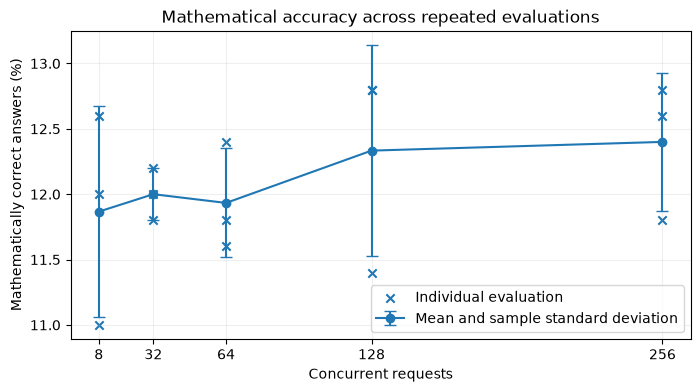

In [4]:
# Show mathematical-verification accuracy and the variability of repeated runs.
figure, axis = plt.subplots(figsize=(8, 4))

axis.errorbar(
  summary["concurrency"],
  summary["math_mean"],
  yerr=summary["math_deviation"],
  fmt="o-",
  capsize=4,
  label="Mean and sample standard deviation",
)

axis.scatter(
  runs["concurrency"],
  runs["math_accuracy_percent"],
  marker="x",
  label="Individual evaluation",
)

axis.set(
  xlabel="Concurrent requests",
  ylabel="Mathematically correct answers (%)",
  title="Mathematical accuracy across repeated evaluations",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
axis.legend()
plt.show()

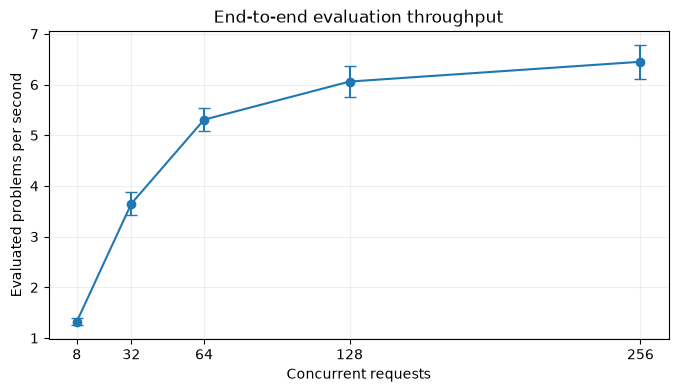

In [5]:
# Compare end-to-end throughput rather than generated tokens per second.
figure, axis = plt.subplots(figsize=(8, 4))

axis.errorbar(
  summary["concurrency"],
  summary["throughput_mean"],
  yerr=summary["throughput_deviation"],
  fmt="o-",
  capsize=4,
)

axis.set(
  xlabel="Concurrent requests",
  ylabel="Evaluated problems per second",
  title="End-to-end evaluation throughput",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
plt.show()

**Observed results.** Mean mathematical-verification accuracy ranged from **11.87% to 12.40%** across concurrency settings, with between-run sample standard deviations of 0.20–0.81 percentage points. No systematic change in accuracy with concurrency was established. End-to-end throughput increased from **1.32 problems/second** at concurrency 8 to **6.45 problems/second** at concurrency 256 (approximately 4.9 times higher). The increase from concurrency 128 to 256 was smaller, from 6.06 to 6.45 problems/second.

## 3. Consistency of individual solutions

Each mathematical problem is compared across its three repetitions at a fixed concurrency setting. A disagreement is recorded when **at least two repetitions differ** in mathematical correctness or complete generated text. These are three-run disagreement rates, not pairwise disagreement probabilities. Text differences need not imply different mathematical conclusions.

A separate diagnostic records the proportion of generated responses without the expected `Final Answer:` phrase. Its absence does not by itself establish truncation or incorrectness.

In [6]:
# Extract per-problem scores and response hashes from the original sample files.
response_records = []

for run in runs.itertuples(index=False):
  sample_files = list((run.directory / "google__gemma-2b").glob("samples_minerva_math500_pinned_*.jsonl"))

  if len(sample_files) != 1:
    raise ValueError(f"Expected exactly one sample file for {run.run}")

  with sample_files[0].open(encoding="utf-8") as file:
    for line in file:
      sample = json.loads(line)
      generated_text = sample["resps"][0][0]

      if not isinstance(generated_text, str):
        raise ValueError(f"Unexpected response format in {run.run}")

      response_records.append({
        "run": run.run,
        "concurrency": run.concurrency,
        "repetition": run.repetition,
        "question": sample["doc_id"],
        "document_hash": sample["doc_hash"],
        "prompt_hash": sample["prompt_hash"],
        "target_hash": sample["target_hash"],
        "math_correct": int(sample["math_verify"]),
        "legacy_correct": int(sample["exact_match"]),
        "has_final_answer": "Final Answer:" in generated_text,
        "text_hash": hashlib.sha256(generated_text.encode("utf-8")).hexdigest(),
      })

responses = pd.DataFrame(response_records)

In [7]:
# Validate completeness, question identity, and agreement with reported scores.
if not responses.groupby("run").size().eq(PROBLEMS_PER_RUN).all():
  raise ValueError("Some evaluations have missing individual responses")

if responses.duplicated(["run", "question"]).any():
  raise ValueError("Duplicate problem within an evaluation")

if not responses.groupby("question")["run"].nunique().eq(len(runs)).all():
  raise ValueError("Problem sets differ between evaluations")

input_changes = responses.groupby("question")[["document_hash", "prompt_hash", "target_hash"]].nunique()

if input_changes.gt(1).any().any():
  raise ValueError("Input problems, prompts, or targets changed between runs")

# Both accuracy metrics must reproduce the aggregate values exactly.
for individual_metric, aggregate_metric in [
  ("math_correct", "math_accuracy_percent"),
  ("legacy_correct", "legacy_accuracy_percent"),
]:
  calculated = 100 * responses.groupby("run")[individual_metric].mean()
  reported = runs.set_index("run")[aggregate_metric]

  if not np.allclose(calculated.loc[reported.index], reported, atol=1e-8):
    raise ValueError(f"Individual scores do not match {aggregate_metric}")

print(f"Validated {len(responses):,} responses to {responses['question'].nunique()} identical problems")

Validated 7,500 responses to 500 identical problems


In [8]:
# Count problems with changing correctness or text over three repetitions.
comparison_records = []

for concurrency, group in responses.groupby("concurrency"):
  math_correct = group.pivot(index="question", columns="repetition", values="math_correct")
  legacy_correct = group.pivot(index="question", columns="repetition", values="legacy_correct")
  generated_texts = group.pivot(index="question", columns="repetition", values="text_hash")

  # More than one distinct value in a row indicates disagreement.
  comparison_records.append({
    "concurrency": concurrency,
    "math_disagreement_percent": 100 * math_correct.nunique(axis=1).gt(1).mean(),
    "legacy_disagreement_percent": 100 * legacy_correct.nunique(axis=1).gt(1).mean(),
    "text_disagreement_percent": 100 * generated_texts.nunique(axis=1).gt(1).mean(),
    "missing_final_answer_percent": 100 * (~group["has_final_answer"]).mean(),
  })

comparison = pd.DataFrame(comparison_records)
display(comparison.round(2))

,concurrency,math_disagreement_percent,legacy_disagreement_percent,text_disagreement_percent,missing_final_answer_percent
0,8,4.6,4.2,44.0,25.73
1,32,6.6,6.2,58.4,27.20
2,64,6.0,5.6,56.0,26.60
3,128,7.2,6.2,58.4,26.60
4,256,7.2,7.0,56.6,26.87


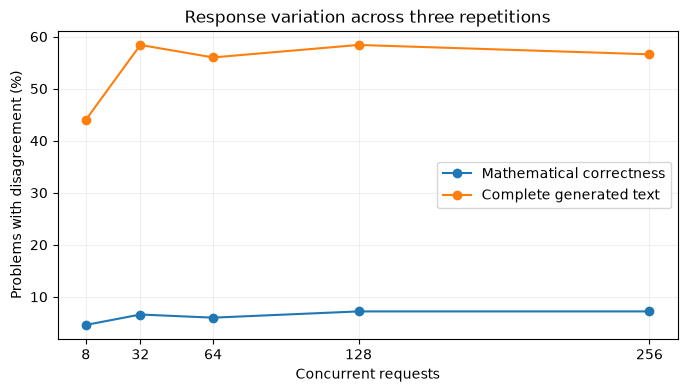

In [9]:
# Visualize changes in mathematical correctness and generated response text.
figure, axis = plt.subplots(figsize=(8, 4))

for metric, label in [
  ("math_disagreement_percent", "Mathematical correctness"),
  ("text_disagreement_percent", "Complete generated text"),
]:
  axis.plot(comparison["concurrency"], comparison[metric], "o-", label=label)

axis.set(
  xlabel="Concurrent requests",
  ylabel="Problems with disagreement (%)",
  title="Response variation across three repetitions",
)
axis.set_xticks(CONCURRENT_REQUESTS)
axis.grid(alpha=0.2)
axis.legend()
plt.show()

**Observed results.** At least one generated text differed across the three repetitions for **44.0–58.4%** of problems, whereas mathematical-correctness ratings changed for only **4.6–7.2%**. Thus, changes in the generated solution frequently left its correctness classification unchanged. The expected `Final Answer:` marker was absent from **25.73–27.20%** of individual responses, depending on concurrency. This marker-based diagnostic does not determine whether a response was truncated.

## 4. Confidence intervals from problem resampling

For each concurrency setting, **5,000 bootstrap samples** are drawn from the 500 problems, with replacement and a fixed random seed. Every sampled problem retains **all three observed repetitions**. The average accuracy is calculated across all sampled answers; disagreement is calculated across the three answers to each sampled problem.

The resulting percentile-based **95% confidence intervals** describe uncertainty associated with the selection of mathematical problems, **conditional on the three observed executions**. They do not predict the result of a future execution or quantify between-run uncertainty; the latter is described separately by the sample standard deviation in Section 2.

In [10]:
# Resample whole problems and preserve their three repeated model responses.
BOOTSTRAP_SAMPLES = 5000
BOOTSTRAP_SEED = 12345

random_generator = np.random.default_rng(BOOTSTRAP_SEED)
interval_records = []

for concurrency, group in responses.groupby("concurrency"):
  math_correct = group.pivot(index="question", columns="repetition", values="math_correct")
  legacy_correct = group.pivot(index="question", columns="repetition", values="legacy_correct")
  generated_texts = group.pivot(index="question", columns="repetition", values="text_hash")

  # Each row now describes one problem using all three original repetitions.
  problem_values = np.column_stack([
    math_correct.to_numpy(dtype=float).mean(axis=1),
    legacy_correct.to_numpy(dtype=float).mean(axis=1),
    math_correct.nunique(axis=1).gt(1).to_numpy(dtype=float),
    generated_texts.nunique(axis=1).gt(1).to_numpy(dtype=float),
  ])

  bootstrap_results = []
  number_of_problems = len(problem_values)

  # Work in batches to avoid allocating all 5,000 sampled datasets at once.
  for start in range(0, BOOTSTRAP_SAMPLES, 100):
    batch_size = min(100, BOOTSTRAP_SAMPLES - start)
    selected_problems = random_generator.integers(
      0, number_of_problems, size=(batch_size, number_of_problems)
    )

    bootstrap_results.append(problem_values[selected_problems].mean(axis=1))

  lower, upper = np.percentile(np.concatenate(bootstrap_results), [2.5, 97.5], axis=0)

  interval_records.append({
    "Concurrent requests": concurrency,
    "Mathematical accuracy, 95% interval (%)": f"{100 * lower[0]:.2f}–{100 * upper[0]:.2f}",
    "Legacy accuracy, 95% interval (%)": f"{100 * lower[1]:.2f}–{100 * upper[1]:.2f}",
    "Correctness disagreement, 95% interval (%)": f"{100 * lower[2]:.2f}–{100 * upper[2]:.2f}",
    "Text disagreement, 95% interval (%)": f"{100 * lower[3]:.2f}–{100 * upper[3]:.2f}",
  })

confidence_intervals = pd.DataFrame(interval_records)
display(confidence_intervals)

,Concurrent requests,"Mathematical accuracy, 95% interval (%)","Legacy accuracy, 95% interval (%)","Correctness disagreement, 95% interval (%)","Text disagreement, 95% interval (%)"
0,8,9.20–14.67,9.13–14.53,2.80–6.60,39.60–48.40
1,32,9.40–14.73,9.00–14.33,4.60–8.80,54.00–62.80
2,64,9.33–14.60,8.93–14.13,4.00–8.20,51.80–60.40
3,128,9.86–15.07,9.87–15.13,5.00–9.60,54.20–62.60
4,256,9.80–15.20,9.33–14.67,5.00–9.60,52.20–61.00


## 5. Interpretation and limitations

The experiment found **similar aggregate mathematical accuracy** across the five concurrency settings despite substantial changes in individual generated solutions. The highest observed end-to-end throughput was at concurrency 256; the three repetitions do not establish that this setting is universally optimal. At concurrency 128, the mean mathematical-verification accuracy was **12.33%**, with a problem-level bootstrap **95% confidence interval of 9.86–15.07%**. The intervals for the other concurrency settings overlap substantially; their overlap alone is not a statistical test of differences.

The bootstrap intervals quantify uncertainty associated with resampling the **500 benchmark problems**, conditional on the three observed executions. They do **not** describe the likely result of a fourth evaluation. Between-run variability is reported separately using sample standard deviations. The two scoring metrics use different extraction and verification procedures, so their differences reflect evaluation methods rather than different model outputs. The absence of `Final Answer:` is not evidence of token-limit exhaustion: the saved response records do not establish the termination reason.

These findings are limited to one model, one fixed dataset and one serving environment. The three repetitions support descriptive analysis but not precise estimates of execution-to-execution uncertainty or causal claims about concurrency. End-to-end throughput includes evaluation and scoring overhead and must not be interpreted as model token-generation speed.